<center>

### **Ilum Escola de Ciência**
#### Bacharelado em Ciência e Tecnologia

<br>

### **Modelos de Aprendizados de Máquina para a Predição de Atividades Antitumorais de Nanocompostos**
#### Trabalho Final da Disciplina de Aprenzidado de Máquina

<br>

**Aluna:** Mariana B. Cavalcanti  
**Professor:** Prof. Dr. Daniel R. Cassar 

<br>

Campinas - SP  
2026

<center>


### 1. Introdução

### 2. Configuração de Ambiente e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dados_literatura = pd.read_csv('nanotox_literatura.csv', sep=',')
dados_validacao = pd.read_csv('nanotox_validacao_externa.csv', sep=',')

### 3. Análise Exploratória dos Dados

#### 3.1 Visão Geral 

In [3]:
resumo_literatura = pd.DataFrame({
    'tipo' : dados_literatura.dtypes.astype(str),
    'n_unicos' : dados_literatura.nunique(),
    'ausentes' : dados_literatura.isna().sum(),
    'ausentes_%' : (dados_literatura.isna().mean() * 100).round(2)
})

resumo_validacao = pd.DataFrame({
    'tipo' : dados_validacao.dtypes.astype(str),
    'n_unicos' : dados_validacao.nunique(),
    'ausentes' : dados_validacao.isna().sum(),
    'ausentes_%' : (dados_validacao.isna().mean() * 100).round(2)
})

print('Resumo dos dados de literatura:')
print(resumo_literatura)
print('\nResumo dos dados de validação:')
print(resumo_validacao)

Resumo dos dados de literatura:
                            tipo  n_unicos  ausentes  ausentes_%
id_linha                   int64      2765         0        0.00
nanoparticula                str        25         0        0.00
revestimento                 str        32      1582       57.22
diametro_nm              float64       117         0        0.00
concentracao_uM          float64       501         0        0.00
potencial_zeta_mV        float64        77         0        0.00
linhagem_celular             str        30         0        0.00
celula_humana_animal         str         2         0        0.00
especie_celula               str         3         0        0.00
morfologia_celular           str         8         0        0.00
orgao_tecido                 str        17         0        0.00
tempo_exposicao_h          int64        20         0        0.00
ensaio                       str        18         0        0.00
indicador_ensaio             str        17         0      

A partir dos dados acima, foi possível perceber que alguns atributos como os descritores quânticos não estam presentes na validação externa.Nesse sentido, o atributo 'revestimento' apresentou elevada proporção de dados ausentes em ambos os conjuntos,provavelmente esses dados devem indicar 'partícula sem revestimento'.Para a validação externa, essa informação não está disponível para nenhuma observação. Além disso, os descritores químico-quânticos estão disponíveis apenas no conjunto de literatura, o que exige estratégias específicas de seleção de atributos para a validação externa. A caracterização dos dados está mais diretamente apresentada na tabela 1.

Tabela 1. Comparação e caracterização dos atributos presentes nos conjuntos de dados nanotox_literatura.csv e nanotox_validacao_externa.csv.
| Característica | Dados de literatura | Validação externa |
|----------------|---------------------|-------------------|
| Número de observações | 2.765 | 240 |
| Número de atributos | 42 | 26 |
| Tipos de nanopartículas | 25 | 6 |
| Linhagens celulares | 30 | 2 |
| Espécies celulares | 3 | 1 |
| Valores ausentes | Apenas em revestimento (57,2%) | Apenas em revestimento (100%) |
| Maior diversidade experimental | Sim | Não |
| Descritores químico-quânticos | Presentes | Ausentes |
| Finalidade | Desenvolvimento dos modelos | Avaliação externa dos modelos |

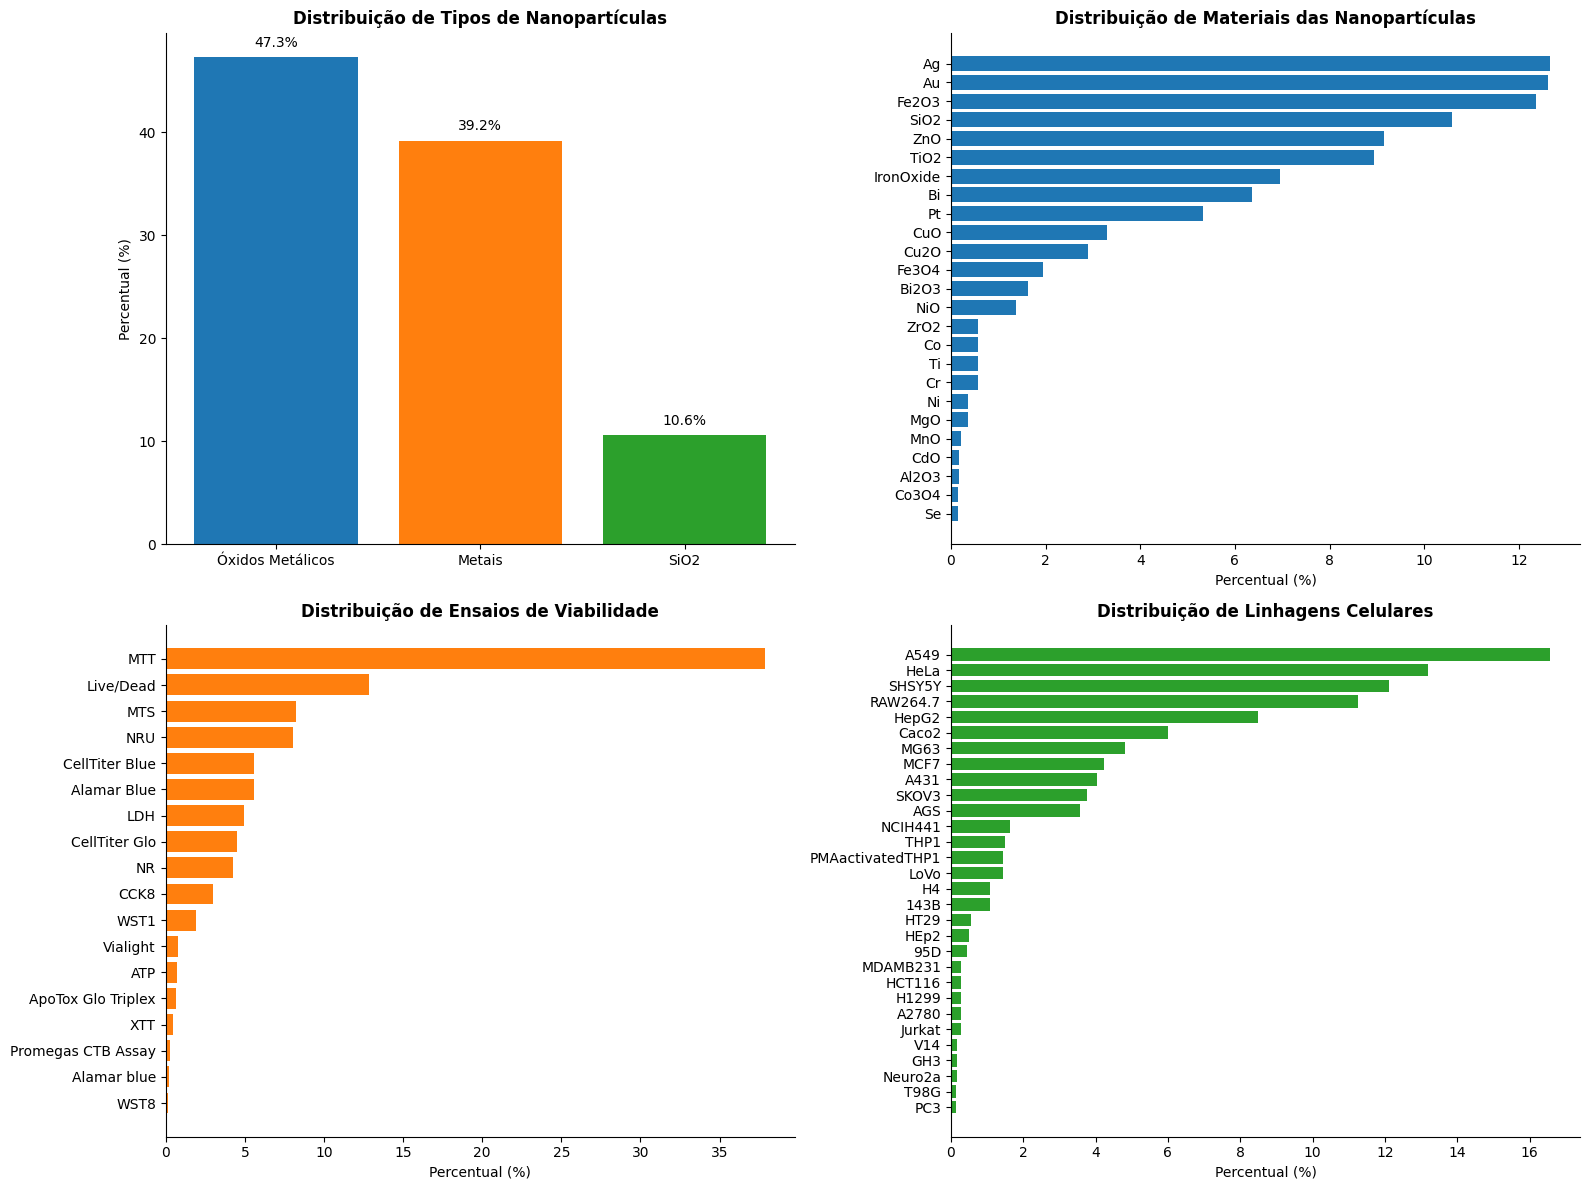

In [4]:
# Organizando os dados

# Classificação das nanopartículas
oxidos_metalicos = [
    'Fe2O3', 'ZnO', 'TiO2', 'IronOxide', 'CuO',
    'Fe3O4', 'Bi2O3','ZrO2', 'CeO2', 'Al2O3', 
    'NiO', 'Co3O4', 'MgO', 'MnO', 'CdO'
]

metais = [
    'Ag', 'Au', 'Co', 'Pt', 
    'Bi','Ni', 'Se', 'Ti', 'Cr'
]

#Contagens e percentuais
total = len(dados_literatura)

n_oxidos_metalicos = dados_literatura['nanoparticula'].isin(oxidos_metalicos).sum()
n_metais = dados_literatura['nanoparticula'].isin(metais).sum()
n_sio2 = (dados_literatura['nanoparticula'] == 'SiO2').sum()

nanoparticulas = pd.DataFrame({
    'Tipo': ['Óxidos Metálicos', 'Metais', 'SiO2'],
    'Percentual': [
        100 * n_oxidos_metalicos / total, 
        100 * n_metais / total, 
        100 * n_sio2 / total]
})

# Materiais das nanopartículas
materiais = (
    dados_literatura['nanoparticula']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)
materiais.columns = ['Material', 'Percentual']

# Ensaios de viabilidade

ensaios = (
    dados_literatura['ensaio']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)

ensaios.columns = ['Ensaio', 'Percentual']

# Linhagens celulares

celulas = (
    dados_literatura['linhagem_celular']
    .value_counts(normalize=True)
    .mul(100)
    .reset_index()
)
celulas.columns = ['Linhagem', 'Percentual']

# Gráficos
fig, axs = plt.subplots(2, 2, figsize=(16, 12))

cores = ['#1f77b4', '#ff7f0e', '#2ca02c']
#1
axs[0, 0].bar(nanoparticulas['Tipo'],nanoparticulas['Percentual'], color=cores)
axs[0, 0].set_title('Distribuição de Tipos de Nanopartículas', fontsize=12, fontweight='bold')
axs[0,0].set_ylabel('Percentual (%)', fontsize=10)

for i, valor in enumerate(nanoparticulas['Percentual']):
    axs[0, 0].text(i, valor + 1, f'{valor:.1f}%', ha='center', fontsize=10)

#2
materiais_ordenados = materiais.sort_values(by='Percentual', ascending=True)

axs[0, 1].barh(materiais_ordenados['Material'], 
              materiais_ordenados['Percentual'], color='#1f77b4')
axs[0, 1].set_title('Distribuição de Materiais das Nanopartículas', fontsize=12, fontweight='bold')
axs[0, 1].set_xlabel('Percentual (%)', fontsize=10)

#3
ensaios_ordenados = ensaios.sort_values(by='Percentual', ascending=True)
axs[1, 0].barh(ensaios_ordenados['Ensaio'], ensaios_ordenados['Percentual'], color='#ff7f0e')
axs[1, 0].set_title('Distribuição de Ensaios de Viabilidade', fontsize=12, fontweight='bold')
axs[1, 0].set_xlabel('Percentual (%)', fontsize=10) 

#4
celulas_ordenadas = celulas.sort_values(by='Percentual', ascending=True)
axs[1, 1].barh(celulas_ordenadas['Linhagem'], celulas_ordenadas['Percentual'], color='#2ca02c')
axs[1, 1].set_title('Distribuição de Linhagens Celulares', fontsize=12, fontweight='bold')
axs[1, 1].set_xlabel('Percentual (%)', fontsize=10)

for ax in axs.flat:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('distribuicao_dados_literatura.png', dpi=300)

plt.show()


Esses gráficos revelam que o conjunto de dados da literatura é predominantemente composto por nanopartículas de óxidos metálicos (50,2%), seguidas por nanopartículas metálicas (39,2%) e nanopartículas de sílica (10,6%). Entre os materiais mais frequentes destacam-se Ag, Au, Fe₂O₃, SiO₂, ZnO e TiO₂. O conjunto apresenta elevada diversidade experimental, evidenciada pela ampla variação de concentrações, tamanhos de partículas e respostas biológicas observadas. Além disso, a diversidade de linhagens celulares e metodologias experimentais reforça a representatividade do conjunto para o desenvolvimento de modelos de predição de toxicidade de nanomateriais.

#### 3.2 Valores discrepantes nas variáveis numéricas

In [5]:
NUMERICAS = [
    "diametro_nm",
    "concentracao_uM",
    "potencial_zeta_mV",
    "tempo_exposicao_h",
    "chi",
    "soma_chi",
    "n_oxigenio_por_soma_chi",
    "n_metal",
    "n_oxigenio",
    "massa_molar",
    "estado_oxidacao",
    "HoF",
    "CA",
    "CV",
    "IP",
    "HOMO",
    "LUMO",
    "NFL",
    "massa_molecular_calc",
    "grupo_pontual",
    "TX",
    "dureza_molecular",
    "eletrofilicidade",
    "Eg",
    "Pol",
    "S"
]

linhas = []

for n in NUMERICAS:
    x = dados_literatura[n]
    q1, mediana, q3 = x.quantile([0.25,0.5,0.75])
    iqr = q3 - q1 
    fora_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    z = ((x - x.mean()) / x.std()).abs()
    positivos = x [x > 0]
    linhas.append({
        "variável" : n,
        "n_unicos" : x.nunique(),
        "min": x.min(),
        "mediana" : mediana,
        "max": x.max(),
        "assimetria": x.skew(),
        "pct_outliers_IQR" : 100* fora_iqr/len(x),
        "n_z_maior_4": int((z > 4).sum()),
        "ordem_magnitude" : np.log10(positivos.max()/ positivos.min() if len(positivos) else np.nan)
    })

tabela = pd.DataFrame(linhas).set_index("variável"). sort_values ("ordem_magnitude", ascending=False)
print(tabela.to_string())
escala = dados_literatura[NUMERICAS].abs().median().replace(0, np.nan)
print(f"Mediana (em módulo) mais baixa e mais alta entre as variáveis numéricas:{escala.min().round(3)} e {escala.max().round(1)}")

                         n_unicos           min      mediana           max  assimetria  pct_outliers_IQR  n_z_maior_4  ordem_magnitude
variável                                                                                                                              
concentracao_uM               501  1.660000e-20    12.571342  16644.474030    6.878557         15.298373           47        24.001162
diametro_nm                   117  1.500000e+00    29.570000    600.000000    2.174451          9.728752           20         2.602060
tempo_exposicao_h              20  1.000000e+00    24.000000    168.000000    1.554625          3.978300           20         2.225309
HoF                            24 -3.117892e+03  -573.499700   2395.876660    0.542079          0.578662            0         2.157125
eletrofilicidade               24  3.001735e-01     4.037221     24.029453    0.967701          0.578662           16         1.903372
Pol                            24  1.788142e+01   209.6

#### 3.3 Definindo o target

Como dito anteriormente nesse trabalho será utilizado um target binário, assim será um problema de classificação. Assim, é necessário que as colunas 'id_linha' seja apagada por ser desnecessária na análise

In [6]:
dados_literatura['target'] = dados_literatura['toxico']
dados_literatura = dados_literatura.drop(columns=['toxico'])
dados_validacao['target'] = dados_validacao['toxico']
dados_validacao = dados_validacao.drop(columns=['toxico'])

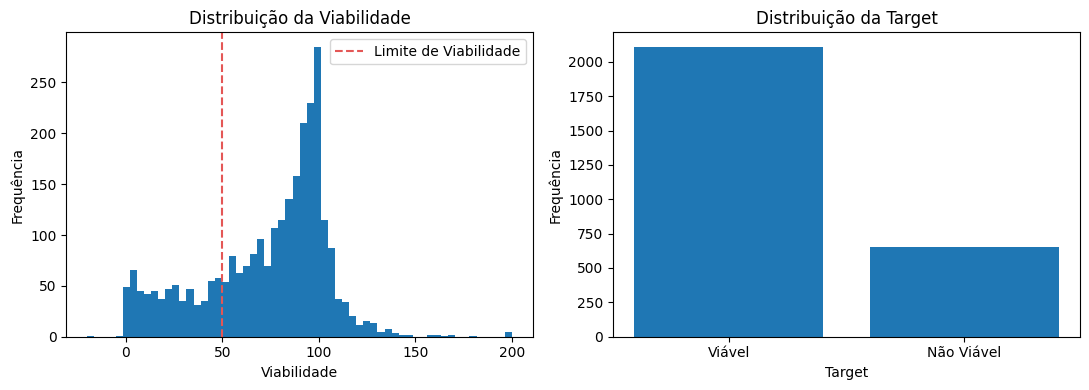

In [7]:
cont = dados_literatura['target'].value_counts().sort_index()
fig, ax = plt.subplots(1, 2,figsize=(11, 4))
ax[0].hist(dados_literatura['viabilidade_pct'].clip(-20,200), bins=60, color=['#1f77b4'])
ax[0].axvline(50, color='#E45756', linestyle='dashed', label='Limite de Viabilidade')
ax[0].set_xlabel('Viabilidade')
ax[0].set_ylabel('Frequência')
ax[0].set_title('Distribuição da Viabilidade')
ax[0].legend()

# Gráfico 2: Distribuição da Target
ax[1].bar(['Viável', 'Não Viável'], cont.values, color=['#1f77b4'])
ax[1].set_xlabel('Target')
ax[1].set_ylabel('Frequência')
ax[1].set_title('Distribuição da Target')

fig.tight_layout()
plt.savefig('distribuicao_viabilidade_target.png', dpi=300)
plt.show()

Assim, é possível perceber que o target deverá ser balanceado no pré-processamento para evitar possíveis outliers, e é necessário que a coluna 'viabilidade_pct' seja apagada para que não ocorra vazamentos dos dados para os modelos.

#### 3.4 Toxidade por nanopartícula

In [8]:
por_np = (
    dados_literatura.groupby('nanoparticula')
    .agg(
        n= ('target', 'size'),
        taxa_toxico = ('target', 'mean'),
        viab_mediana=('viabilidade_pct', 'median')
    )
    .sort_values('taxa_toxico', ascending=False)
)
print('Resumo por nanopartícula:')
print(por_np.round(3).to_string())

Resumo por nanopartícula:
                 n  taxa_toxico  viab_mediana
nanoparticula                                
CdO              5        1.000         2.578
Co3O4            4        0.750        33.174
Ni              10        0.500        50.493
MgO             10        0.500        62.130
Ag             350        0.497        50.568
Al2O3            5        0.400        54.026
NiO             38        0.395        64.547
ZrO2            16        0.375        54.200
Co              16        0.375        70.679
CuO             91        0.363        66.055
Cu2O            80        0.362        84.656
Pt             147        0.361        65.187
MnO              6        0.333        68.932
ZnO            253        0.324        68.577
Se               4        0.250        65.917
Bi2O3           45        0.244        67.672
SiO2           293        0.188        76.678
Fe2O3          342        0.155        88.877
Au             349        0.152        89.630
Bi      

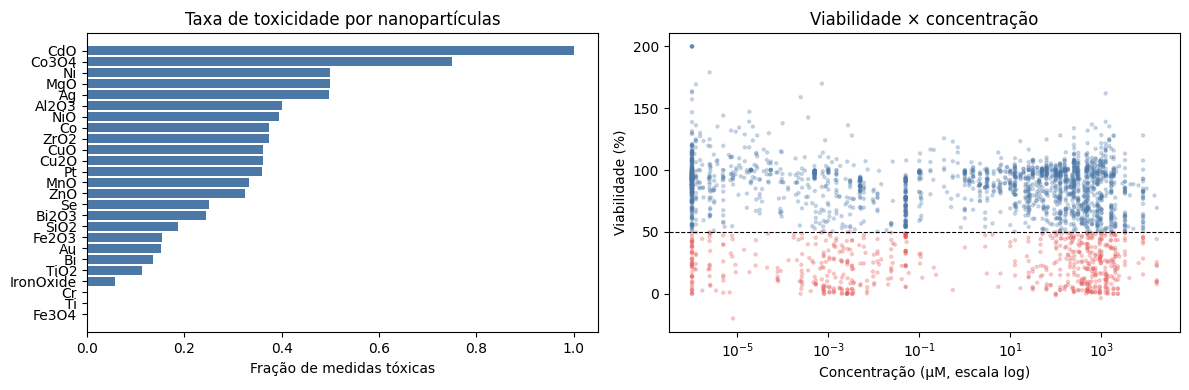

In [9]:
fig,ax = plt.subplots(1, 2, figsize = (12, 4))

ordem = por_np.sort_values('taxa_toxico').index

ax[0].barh(
    ordem,
    por_np.loc[ordem,'taxa_toxico'],
    color = '#4C78A8'
)

ax[0].set_xlabel('Fração de medidas tóxicas')
ax[0].set_title('Taxa de toxicidade por nanopartículas')

ax[1].scatter(
    dados_literatura['concentracao_uM'].clip(lower=1e-6),
    dados_literatura['viabilidade_pct'].clip(-20, 200),
    s=5,
    alpha=0.25,
    c=np.where(
        dados_literatura['target'] == 1,
        "#E45756",
        "#4C78A8"
    )
)


ax[1].set_xscale("log")
ax[1].axhline(
    50,
    color="k",
    ls="--",
    lw=0.8
)

ax[1].set_xlabel("Concentração (µM, escala log)")
ax[1].set_ylabel("Viabilidade (%)")
ax[1].set_title("Viabilidade × concentração")

plt.tight_layout()
plt.show()

#### 3.5 Descritores Quânticos

In [10]:
QUANTICOS = [
    "HoF",
    "CA",
    "CV",
    "IP",
    "HOMO",
    "LUMO",
    "NFL",
    "massa_molecular_calc",
    "grupo_pontual",
    "TX",
    "dureza_molecular",
    "eletrofilicidade",
    "Eg",
    "Pol",
    "S"
]
df = dados_literatura.copy()

In [11]:
# Descobrindo quantos valores distintos existem
print(f"Valores distintos por descritor quântico (em {len(df)} linhas):")
print(df[QUANTICOS].nunique().to_string())

# Cada combinação dos descritores é igual a um perfil quântico

df["perfil_quantico"] = (
    df.groupby(QUANTICOS, dropna=False)
      .ngroup()
)

print(
    "\nPerfis quânticos distintos:",
    df["perfil_quantico"].nunique(),
    "| nanopartículas:",
    df["nanoparticula"].nunique()
)

# Descobrindo se o perfil quântico é fixo por nanopartícula 

moda = (
    df.groupby("nanoparticula")["perfil_quantico"]
      .agg(lambda s: s.mode().iloc[0])
)

fora = (
    df["perfil_quantico"] !=
    df["nanoparticula"].map(moda)
)

print(
    f"Linhas com o perfil típico da sua nanopartícula: {(~fora).mean():.1%} "
    f"| fora do típico: {fora.sum()} ({fora.mean():.1%})"
)

print("\nNanopartículas com mais de um perfil quântico:")

print(
    df.groupby("nanoparticula")["perfil_quantico"]
      .nunique()
      .loc[lambda s: s > 1]
      .sort_values(ascending=False)
      .to_string()
)

Valores distintos por descritor quântico (em 2765 linhas):
HoF                     24
CA                      24
CV                      24
IP                      24
HOMO                    24
LUMO                    24
NFL                     22
massa_molecular_calc    24
grupo_pontual            9
TX                      24
dureza_molecular        24
eletrofilicidade        24
Eg                      24
Pol                     24
S                       24

Perfis quânticos distintos: 24 | nanopartículas: 25
Linhas com o perfil típico da sua nanopartícula: 94.1% | fora do típico: 163 (5.9%)

Nanopartículas com mais de um perfil quântico:
nanoparticula
Fe2O3    9
Au       5
Bi       2
Co       2
Cr       2
CuO      2
SiO2     2
Ti       2
TiO2     2
ZnO      2


Assim, os descritores químico-quânticos apresentam baixa variabilidade ao longo dos experimentos, caracterizando propriedades intrínsecas dos materiais. A maioria dos descritores avaliados apresentou 24 valores distintos em um conjunto contendo 2.765 observações e 25 nanopartículas diferentes. No entanto, as nanopartículas de Fe2O3 apresentara varios perfis distintos, logo é necessário uma verificação das possíveis causas.

In [12]:
dados_literatura.loc[
    dados_literatura["nanoparticula"] == "Fe2O3",
    QUANTICOS
].drop_duplicates()

,HoF,CA,CV,IP,HOMO,LUMO,NFL,massa_molecular_calc,grupo_pontual,TX,dureza_molecular,eletrofilicidade,Eg,Pol,S
1137,-1243.55440,408.48,633.93,10.715248,-10.715,-4.819,128,1165.8436,2,7.7670,2.9480,10.231732,5.896,52.909352,0.339213
1152,2395.87666,516.82,985.89,5.288031,-5.288,-0.329,96,1663.8720,2,2.8085,2.4795,1.590577,4.959,327.214430,0.403307
1156,-573.49970,310.43,449.67,7.776280,-7.776,-0.290,170,1590.9080,5,4.0330,3.7430,2.172734,7.486,115.190620,0.267165
1209,-77.49302,435.09,733.47,10.555741,-9.069,-4.760,108,1267.8136,2,6.9145,2.1545,11.095454,4.309,361.025102,0.464145
1285,1274.31384,543.40,1045.94,7.872196,-7.872,-5.899,44,1053.8000,8,6.8855,0.9865,24.029453,1.973,691.865878,1.013685
1299,-725.87448,322.92,463.16,5.915940,-5.916,-2.018,62,1351.4510,2,3.9670,1.9490,4.037221,3.898,216.666380,0.513084
1309,-122.60844,372.66,567.35,5.176822,-6.209,0.319,104,3742.3635,1,2.9450,3.2640,1.328588,6.528,209.627450,0.306373
1316,-855.36225,348.90,495.89,7.043021,-7.043,-2.143,56,472.8478,3,4.5930,2.4500,4.305234,4.900,412.022540,0.408163
1411,-1395.23559,502.72,681.67,10.088616,-10.089,-3.015,108,911.0820,2,6.5520,3.5370,6.068519,7.074,277.174898,0.282725


Logo, as discrepâncias observadas em Fe₂O₃, que apresentou nove perfis distintos, são causadas, possivelmente, pelas diferenças dos calculos para a fórmula Fe2O3, o que indica que foram usadas diferentes tamanhos de clusters mas só foi indicado o mínimo, as diferenças nas massas moleculares são fortes indícios dessa hipótese. 

#### 3.6 As estruturas experimentais distintas

Para analisarmos quantos experimentos foram feitos de forma distinta, é necessario que um experimento tenha a mesma nanopartícula, célula e mesmas condições experimentais, ou seja, um experimento é composto por combinações únicas de nanopartícula, revestimento, tamanho, potencial zeta, linhagem celular, ensaio, tempo de exposição. Nessa análise consideramos que a concentração pode variar.

In [13]:

CHAVE_EXP = [
    "nanoparticula",
    "revestimento",
    "diametro_nm",
    "potencial_zeta_mV",
    "linhagem_celular",
    "ensaio",
    "tempo_exposicao_h"
]

df["id_experimento"] = (
    df.groupby(CHAVE_EXP, dropna=False)
      .ngroup()
)

tam = df.groupby("id_experimento").size()

print("Experimentos distintos:", df["id_experimento"].nunique())
print(
    "Medidas por experimento — mediana:",
    int(tam.median()),
    "| máx:",
    tam.max()
)

print("\nMedidas por nanopartícula (desbalanceio entre grupos):")
print(df["nanoparticula"].value_counts().to_string())

Experimentos distintos: 621
Medidas por experimento — mediana: 5 | máx: 10

Medidas por nanopartícula (desbalanceio entre grupos):
nanoparticula
Ag           350
Au           349
Fe2O3        342
SiO2         293
ZnO          253
TiO2         247
IronOxide    192
Bi           176
Pt           147
CuO           91
Cu2O          80
Fe3O4         54
Bi2O3         45
NiO           38
Co            16
Cr            16
Ti            16
ZrO2          16
MgO           10
Ni            10
MnO            6
Al2O3          5
CdO            5
Co3O4          4
Se             4


A análise da estrutura experimental do conjunto de literatura identificou 621 experimentos distintos. Foram observadas 2.765 medições, correspondendo a uma mediana de cinco concentrações avaliadas por experimento e máximo de dez concentrações por ensaio. Esse resultado demonstra que grande parte dos estudos investigou respostas das doses dos nanomateriais. Em relação à distribuição das nanopartículas, observou-se forte desbalanceamento entre os materiais avaliados. As nanopartículas Ag, Au, Fe₂O₃, SiO₂, ZnO e TiO₂ concentraram aproximadamente 66,3% de todas as observações do conjunto, enquanto materiais como Se, Co₃O₄, CdO e Al₂O₃ apresentaram menos de dez registros cada. Embora o conjunto apresente elevada diversidade experimental, abrangendo 25 nanomateriais distintos e 30 linhagens celulares, a diferença de representatividade entre os materiais será considerada na interpretação dos resultados e na avaliação dos modelos preditivos de toxicidade.

#### 3.7 Correlação das variáveis numéricas

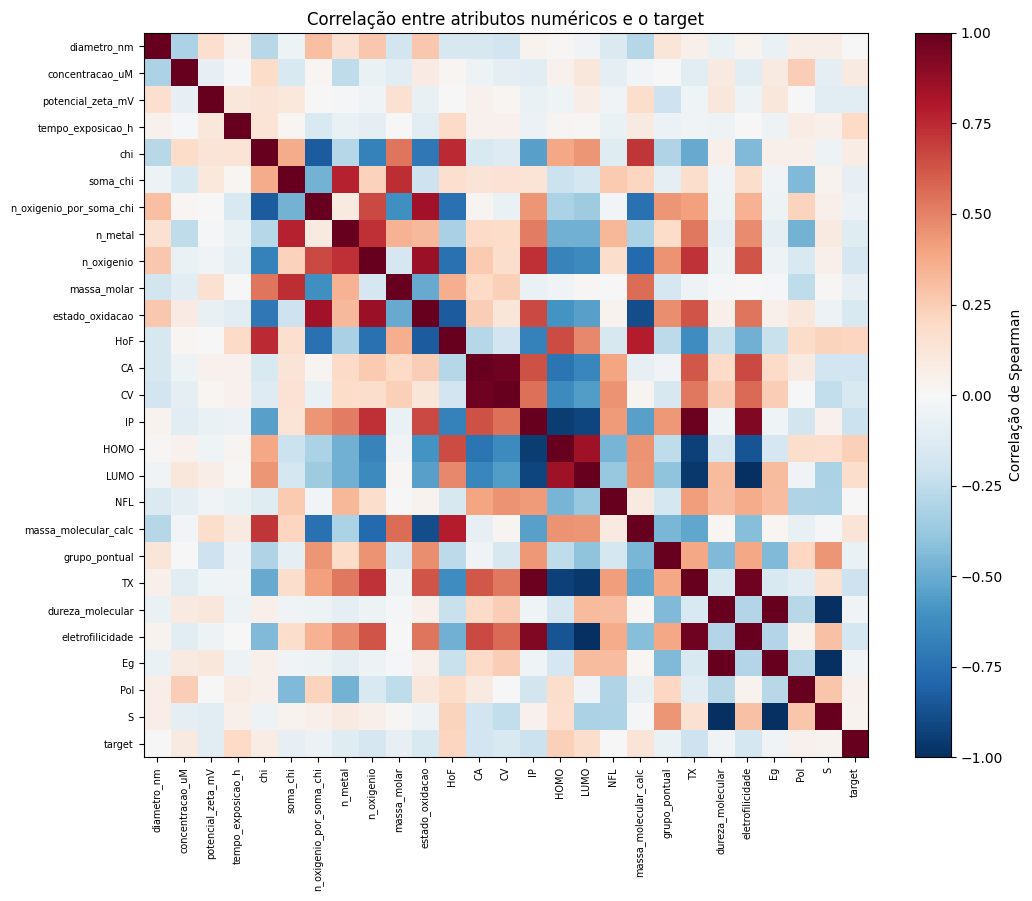

Pares com |rho| > 0.95 (candidatos à redundância): 9

Top 10 variáveis mais correlacionadas com o target:
HOMO                 0.241
IP                   0.217
HoF                  0.214
TX                   0.204
tempo_exposicao_h    0.199
CA                   0.193
eletrofilicidade     0.179
LUMO                 0.177
n_oxigenio           0.168
estado_oxidacao      0.150

Pares com |rho| > 0.95:
Eg                S                   1.000
dureza_molecular  S                   1.000
                  Eg                  1.000
LUMO              eletrofilicidade    0.997
IP                TX                  0.978
CA                CV                  0.975
TX                eletrofilicidade    0.971
LUMO              TX                  0.967
IP                HOMO                0.950


In [14]:

corr = dados_literatura[NUMERICAS + ["target"]].corr(
    method="spearman"
)

fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    corr,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(corr)))
ax.set_xticklabels(
    corr.columns,
    rotation=90,
    fontsize=7
)

ax.set_yticks(range(len(corr)))
ax.set_yticklabels(
    corr.columns,
    fontsize=7
)

fig.colorbar(
    im,
    ax=ax,
    label="Correlação de Spearman"
)

ax.set_title(
    "Correlação entre atributos numéricos e o target"
)

plt.tight_layout()
plt.show()

# Pares altamente correlacionados

alta = (
    corr.abs()
        .where(
            np.triu(
                np.ones(corr.shape),
                1
            ).astype(bool)
        )
        .stack()
        .sort_values(ascending=False)
)

print(
    "Pares com |rho| > 0.95 (candidatos à redundância):",
    int((alta > 0.95).sum())
)

print("\nTop 10 variáveis mais correlacionadas com o target:")

print(
    corr["target"]
    .drop("target")
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .round(3)
    .to_string()
)

print("\nPares com |rho| > 0.95:")

print(
    alta[alta > 0.95]
    .round(3)
    .to_string()
)

#### 3.8 Conjunto de validação externa

In [15]:
print('Nanopartículas da validação externa', sorted(dados_validacao['nanoparticula'].unique()))
print('Inéditas(não existentes na literatura):', sorted(set(dados_validacao['nanoparticula'].unique()) - set(dados_literatura['nanoparticula'].unique())))
print('Tóxicos na validação externa:', sorted(dados_validacao.loc[dados_validacao['target'] == 1, 'nanoparticula'].unique()))
print('Colunas que a validação externa não tem:', sorted(set(dados_literatura.columns) - set(dados_validacao.columns)))

Nanopartículas da validação externa ['CdO', 'CeO2', 'Cu2O', 'Er2O3', 'Nd2O3', 'ZnO']
Inéditas(não existentes na literatura): ['CeO2', 'Er2O3', 'Nd2O3']
Tóxicos na validação externa: ['ZnO']
Colunas que a validação externa não tem: ['CA', 'CV', 'Eg', 'HOMO', 'HoF', 'IP', 'LUMO', 'NFL', 'Pol', 'S', 'TX', 'dureza_molecular', 'eletrofilicidade', 'grupo_pontual', 'massa_molecular_calc']


### 4. Pré-processamento dos dados

### 5. Modelo Baseline 

### 6. Otimização de Hiperpâmetros

### 7. Modelos 

### 8. Resultados e Comparações

### 9. Conclusão

### Referências



#### Interação com IA